#Experiment 5: Reinforcement learning

 Example 1: The environment

In [3]:
import numpy as np

H, W = 5, 7
WALLS = {(1,2), (2,2), (3,2), (1,4), (2,4)}
GOAL, PIT, START = (0, W-1),(2,W-1), (H-1, 0)
A = [(-1,0), (1,0), (0,-1), (0,1)]  # up, down, left, right

def step(s, a):
    r, c = s; dr, dc = A[a]; nr, nc = r+dr, c+dc
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c  # bumping a wall also wastes the step

    ns = (nr, nc)
    if ns == GOAL: return ns, +10.0, True
    if ns == PIT: return ns, -10.0, True
    return ns, -0.1, False  # small cost per step

Example 2: Q-learning


In [4]:
def train(eps, episodes=600, alpha=0.5, gamma=0.95, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    curve = []

    for _ in range(episodes):
        s, total = START, 0.0
        for _ in range(120):  # step cap
            if rng.random() < eps:
                a = rng.integers(4)  # explore
            else:
                a = int(np.argmax(Q[s[0], s[1]]))  # exploit

            ns, r, done = step(s, a)
            total += r
            Q[s[0], s[1], a] += alpha * (
                r + gamma * np.max(Q[ns[0], ns[1]]) * (not done)
                - Q[s[0], s[1], a]
            )
            s = ns
            if done:
                break

        curve.append(total)

    return Q, np.array(curve)

 Example 3: Exploration rate, and reading the policy


eps=0.05: mean return over last 100 episodes = 8.86
eps=0.2: mean return over last 100 episodes = 8.86
eps=0.5: mean return over last 100 episodes = 7.44


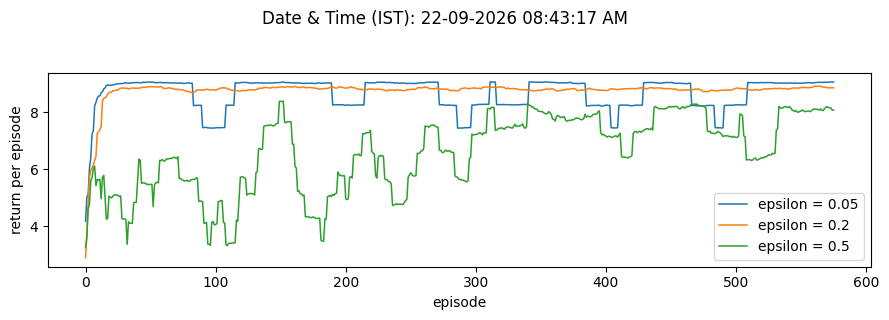

In [7]:
import matplotlib.pyplot as plt

def smooth(v, k=25):
    return np.convolve(v, np.ones(k)/k, mode='valid')

plt.figure(figsize=(9, 3))

from datetime import datetime
from zoneinfo import ZoneInfo

ist_now = datetime.now(ZoneInfo("Asia/Kolkata"))
plt.suptitle(
    f"Date & Time (IST): {ist_now.strftime('%d-%m-%Y %I:%M:%S %p')}",
    y=1.05
)

for eps in (0.05, 0.20, 0.50):
    Q, curve = train(eps)
    plt.plot(smooth(curve), lw=1.1, label=f'epsilon = {eps}')
    print(f'eps={eps}: mean return over last 100 episodes = '
          f'{curve[-100:].mean():.2f}')

plt.xlabel('episode'); plt.ylabel('return per episode')
plt.legend(); plt.tight_layout(); plt.show()

Q, _ = train(0.20)
policy = np.argmax(Q, axis=2)  # greedy action in every cell

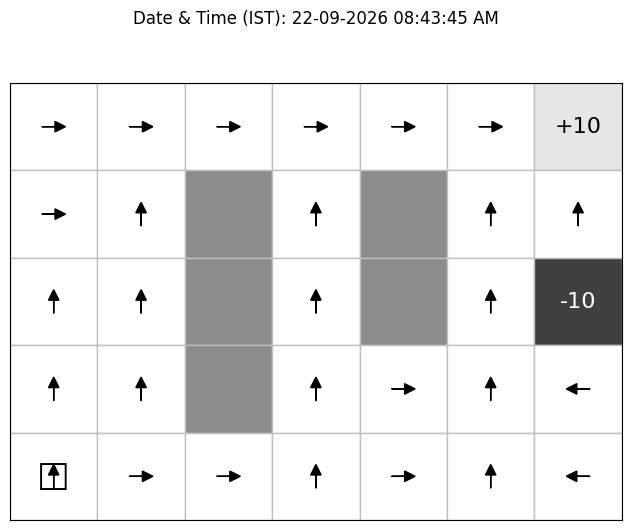

In [8]:
Q, _ = train(0.20)
policy = np.argmax(Q, axis=2)  # greedy action in every cell


# Visualize the greedy policy

fig, ax = plt.subplots(figsize=(9, 5))
from datetime import datetime
from zoneinfo import ZoneInfo

ist_now = datetime.now(ZoneInfo("Asia/Kolkata"))
plt.suptitle(
    f"Date & Time (IST): {ist_now.strftime('%d-%m-%Y %I:%M:%S %p')}",
    y=1.05
)
for r in range(H):
    for c in range(W):
        facecolor = 'white'

        if (r, c) in WALLS:
            facecolor = '0.55'
        elif (r, c) == GOAL:
            facecolor = '0.90'
        elif (r, c) == PIT:
            facecolor = '0.25'

        rect = plt.Rectangle(
            (c, H - 1 - r), 1, 1,
            facecolor=facecolor,
            edgecolor='0.75',
            linewidth=1
        )
        ax.add_patch(rect)

directions = {
    0: (0, 0.30),    # up
    1: (0, -0.30),   # down
    2: (-0.30, 0),   # left
    3: (0.30, 0)     # right
}

for r in range(H):
    for c in range(W):

        if (r, c) in WALLS:
            continue

        if (r, c) == GOAL:
            ax.text(
                c + 0.5, H - 1 - r + 0.5,
                '+10',
                ha='center',
                va='center',
                fontsize=16
            )
            continue

        if (r, c) == PIT:
            ax.text(
                c + 0.5, H - 1 - r + 0.5,
                '-10',
                ha='center',
                va='center',
                fontsize=16,
                color='white'
            )
            continue

        if (r, c) == START:
            ax.text(
                c + 0.5, H - 1 - r + 0.5,
                '□',
                ha='center',
                va='center',
                fontsize=25
            )

        action = policy[r, c]
        dx, dy = directions[action]

        x = c + 0.5
        y = H - 1 - r + 0.5

        ax.arrow(
            x - dx * 0.45,
            y - dy * 0.45,
            dx * 0.9,
            dy * 0.9,
            head_width=0.12,
            head_length=0.12,
            fc='black',
            ec='black',
            length_includes_head=True
        )

ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()